# Employee Attrition: EDA
Goal: understand the data and what drives people to leave.

In [8]:

import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "WA_Fn-UseC_-HR-Employee-Attrition.csv"   # sirf naam, koi folder nahi

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "pavansubhasht/ibm-hr-analytics-attrition-dataset",
    file_path,
)
df.shape


print("First 5 records:", df.head())

C:\Users\hp\AppData\Local\Temp\ipykernel_22356\1265670762.py:6: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


First 5 records:    Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  StockOpti

In [11]:
import kagglehub, shutil

path = kagglehub.dataset_download("pavansubhasht/ibm-hr-analytics-attrition-dataset")
shutil.copy(f"{path}/WA_Fn-UseC_-HR-Employee-Attrition.csv", "../data/")


'../data/WA_Fn-UseC_-HR-Employee-Attrition.csv'

In [13]:
df = pd.read_csv("../data/WA_Fn-UseC_-HR-Employee-Attrition.csv")
df.shape

(1470, 35)

## 1. Basic checks

In [14]:
df.info()
print(df.isna().sum().sum(), "missing values;", df.duplicated().sum(), "duplicate rows")
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


In [15]:
# columns with a single value or pure IDs are useless
print(df.nunique().sort_values().head(8))

EmployeeCount        1
Over18               1
StandardHours        1
Attrition            2
OverTime             2
PerformanceRating    2
Gender               2
BusinessTravel       3
dtype: int64


## 2. Target distribution (class imbalance)

Attrition
No     0.838776
Yes    0.161224
Name: proportion, dtype: float64


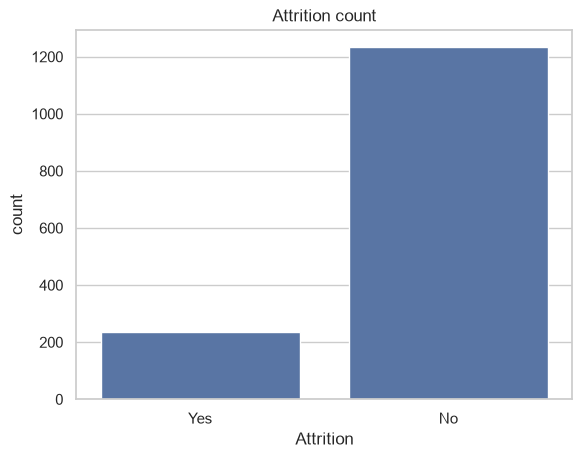

In [16]:
print(df["Attrition"].value_counts(normalize=True))
sns.countplot(data=df, x="Attrition")
plt.title("Attrition count"); plt.show()

## 3. Clean

In [17]:
df = df.drop(columns=["EmployeeCount","EmployeeNumber","Over18","StandardHours"])
df["Attrition_flag"] = (df["Attrition"] == "Yes").astype(int)

## 4. Attrition rate by category

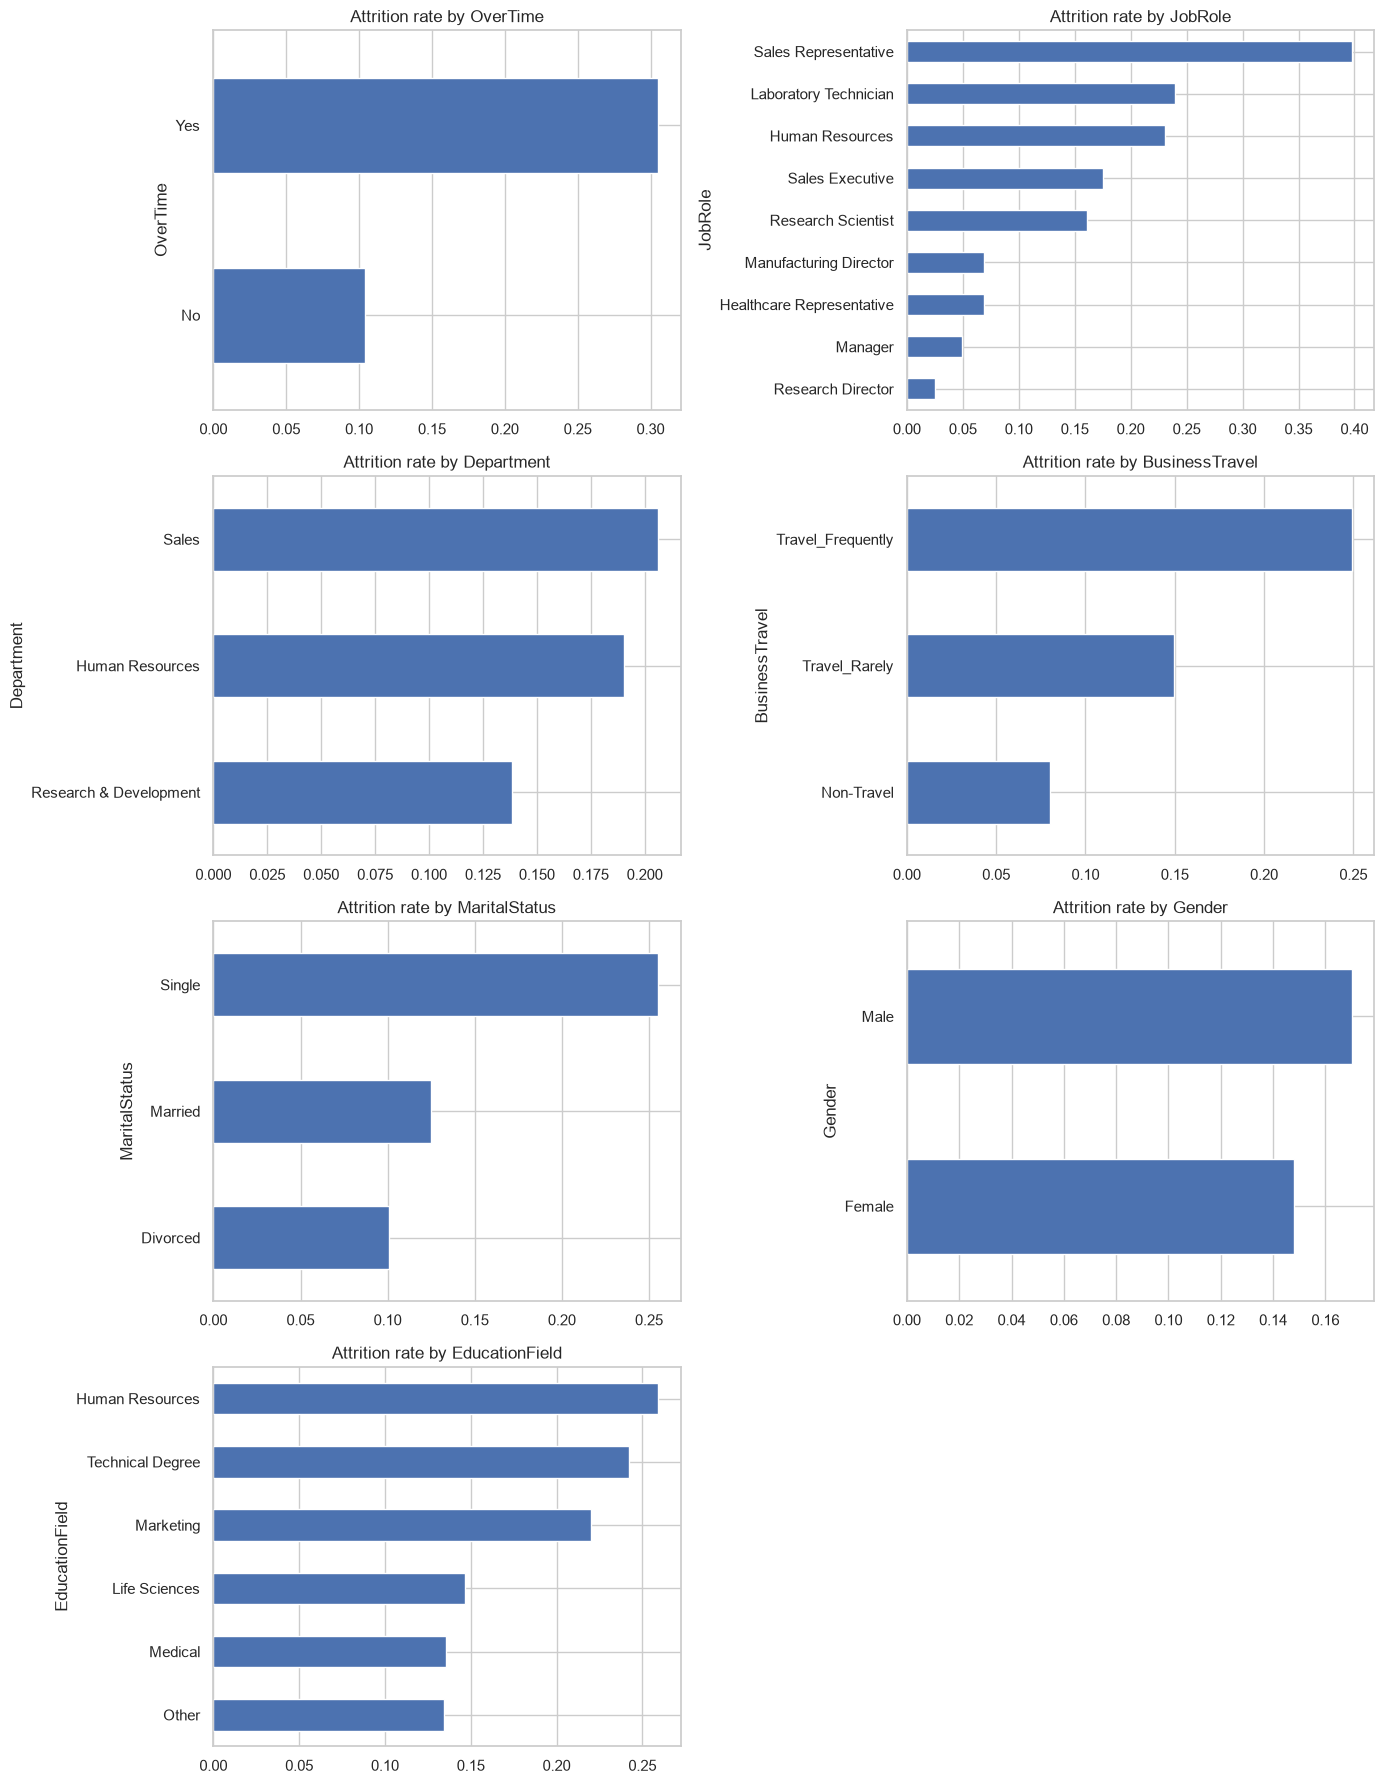

In [18]:
cat_cols = ["OverTime","JobRole","Department","BusinessTravel","MaritalStatus","Gender","EducationField"]
fig, axes = plt.subplots(4, 2, figsize=(14, 18))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = df.groupby(col)["Attrition_flag"].mean().sort_values()
    rate.plot(kind="barh", ax=ax); ax.set_title(f"Attrition rate by {col}")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

## 5. Numeric features vs attrition

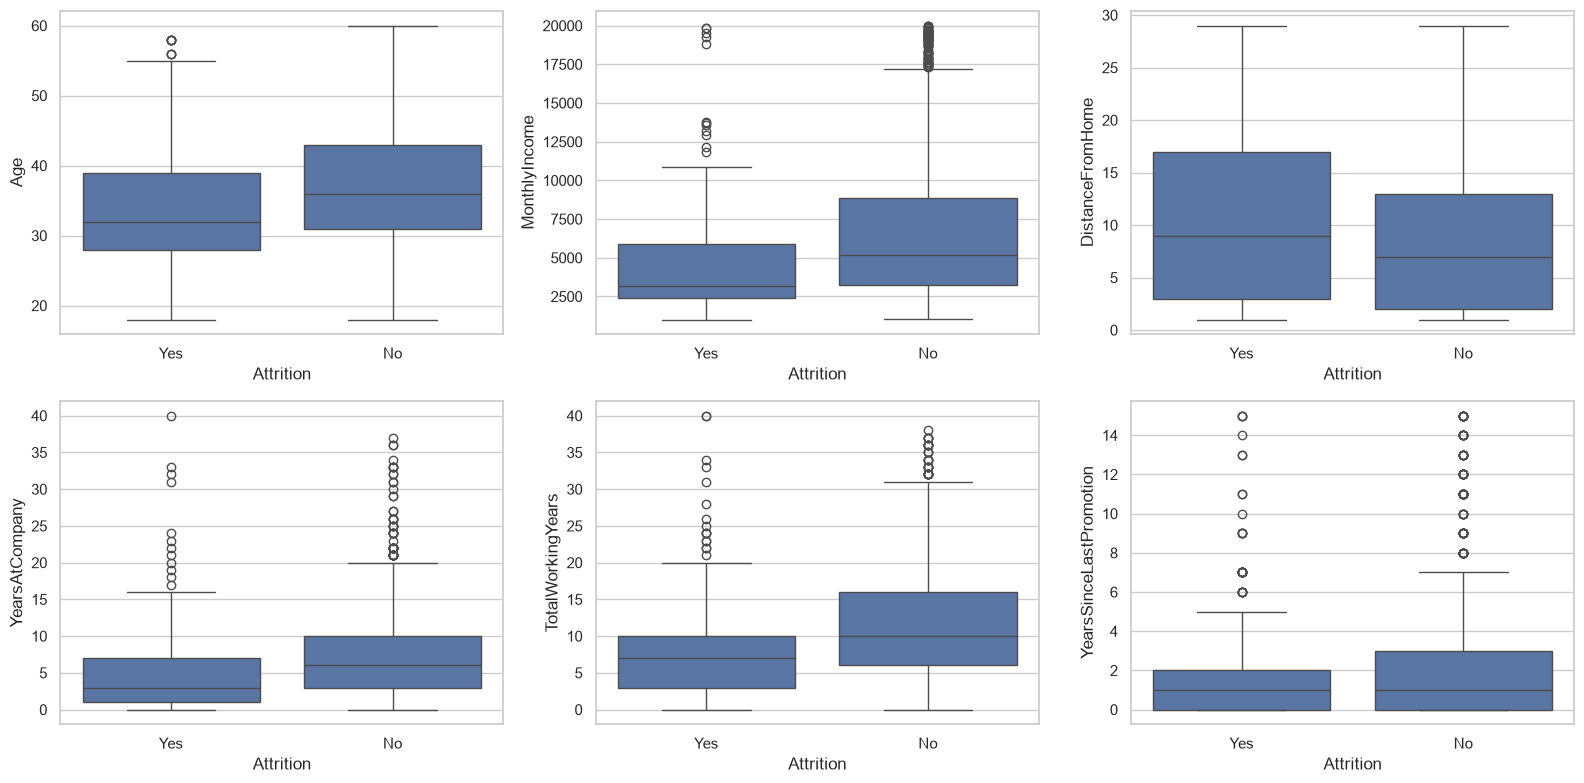

In [19]:
num_cols = ["Age","MonthlyIncome","DistanceFromHome","YearsAtCompany","TotalWorkingYears","YearsSinceLastPromotion"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x="Attrition", y=col, ax=ax)
plt.tight_layout(); plt.show()

## 6. Correlation

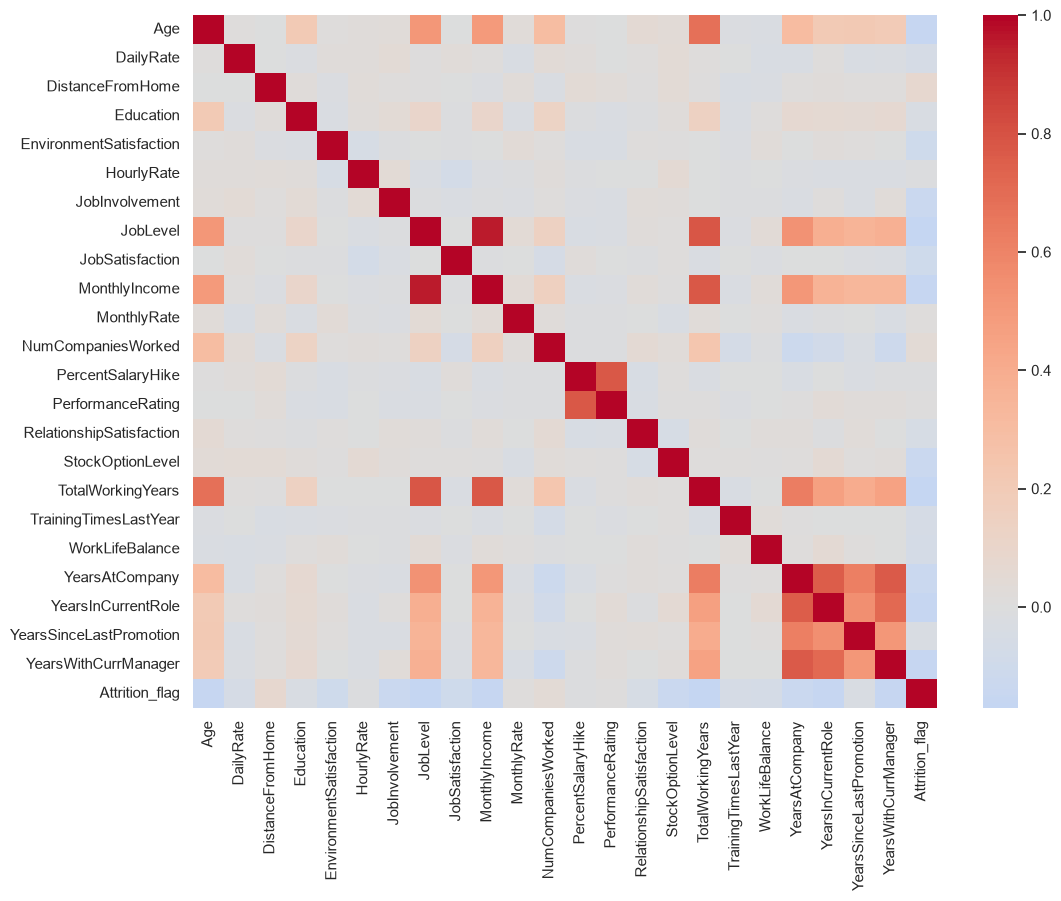

TotalWorkingYears          -0.171063
JobLevel                   -0.169105
YearsInCurrentRole         -0.160545
MonthlyIncome              -0.159840
Age                        -0.159205
YearsWithCurrManager       -0.156199
StockOptionLevel           -0.137145
YearsAtCompany             -0.134392
JobInvolvement             -0.130016
JobSatisfaction            -0.103481
EnvironmentSatisfaction    -0.103369
WorkLifeBalance            -0.063939
TrainingTimesLastYear      -0.059478
DailyRate                  -0.056652
RelationshipSatisfaction   -0.045872
YearsSinceLastPromotion    -0.033019
Education                  -0.031373
PercentSalaryHike          -0.013478
HourlyRate                 -0.006846
PerformanceRating           0.002889
MonthlyRate                 0.015170
NumCompaniesWorked          0.043494
DistanceFromHome            0.077924
Name: Attrition_flag, dtype: float64

In [20]:
corr = df.select_dtypes("number").corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.show()
corr["Attrition_flag"].drop("Attrition_flag").sort_values()

## 7. Findings
_Write your own insights here (e.g. overtime effect, low income, early-tenure exits)._